In [245]:
from rlcard.agents import  (CFRAgent,
    RandomAgent)
from collections import defaultdict
import rlcard
from rlcard.utils import print_card
from rlcard.envs import Env
from scipy import stats
import numpy as np
from matplotlib import pyplot as plt


In [246]:

class NormalGamma:


    def __init__(self, mu, lmbda, alpha, beta):
        self.mu = mu
        self.lmbda = lmbda
        self.alpha = alpha
        self.beta = beta

    def __repr__(self):
        return (f"NG(mu = {self.mu}, lambda = {self.lmbda}, alpha = {self.alpha}, beta = {self.beta})")

    def sample_normal_gamma(self, size = 1):

        
        rng = np.random.default_rng()

        tau = rng.gamma(shape= self.alpha, scale = 1.0 / self.beta, size = size)

        std_dev = 1.0 / np.sqrt(self.lmbda * tau)

        x = rng.normal(loc = self.mu, scale = std_dev, size = size)

        return x, tau

    

    def update(self, R=None, M1=None, M2=None):

        n = 1

        if M1 is None and M2 is None:
            n = 1 if np.isscalar(R) else len(R)
            M1 = 1/n * np.sum(R)
            M2 = 1/ n * np.sum(R*R)
        
        beta = self.beta + 1/2 * n* ( M2 - M1 **2) + n * self.lmbda* ( M1 - self.mu) **2 / (2* self.lmbda + 2* n)
        mu = (self.lmbda * self.mu + n * M1) / (self.lmbda + n)
        lmbda = self.lmbda + n
        alpha = self.alpha + 1/2 * n
        self.mu = mu
        self.lmbda = lmbda
        self.beta = beta
        self.alpha = alpha


    
    

In [247]:


class BayesianAgent:
    def __init__(
            self,
            env : Env,
            model_path,
            num_actions,
            prior_mu = 0,
            prior_lmbda = 1,
            prior_a = 2,
            prior_b = 20,
        ) -> None:
            self.num_actions = num_actions
            self.use_raw = False
            self.env = env 
            self.iteration = 0
            self.q = defaultdict(self._defaultdistribution)
            self.cost = 0
            self.gamma = 1

            self.prior_mu = prior_mu
            self.prior_lmbda = prior_lmbda
            self.prior_a = prior_a
            self.prior_b = prior_b

            self.trained_against = None



    def __str__(self):
        return f"BayesianAgent trained with {self.trained_against}, (γ={self.gamma}, r={self.cost}, μ={self.prior_lmbda}, α={self.prior_a}, β={self.prior_b})"            

    def _defaultdistribution(self):
        return [NormalGamma(self.prior_mu, self.prior_lmbda, self.prior_a, self.prior_b) for _ in range(self.num_actions)]

    @staticmethod
    def _state_key(state: dict) -> bytes:
        """
        RLCard's observation is the information available to the player.
        Using obs rather than raw game state avoids giving the agent hidden
        cards/information.
        """
        obs = np.asarray(state["obs"], dtype=np.float32)
        return obs.tobytes()
    
    def _get_self_id(self):

        for i, agent in enumerate(self.env.agents):
            if agent is self:
                return i

    def _intermediate_update(self,state, state_key, prev_state_key, bayesian_action):

        best, info = self.eval_step(state)
        R = self.q[state_key][best]
        mu, lmbda, beta, alpha  = R.mu, R.lmbda, R.beta, R.alpha
        gamma = self.gamma
        cost = self.cost
        ER = mu
        ER2 = (lmbda + 1)/ lmbda * (beta)/ (alpha - 1) + mu*mu
        M1 = cost + gamma * ER
        M2 = cost * cost + 2 * gamma * cost *ER + gamma * gamma * ER2

        self.q[prev_state_key][bayesian_action].update(M1=M1, M2=M2)
        
    def _get_costs_of_actions(self, state):
        
        raise_amount = 2 if state['raw_obs']['public_card'] is None else 4
        costs = {}
        costs['call'] = (max(state['raw_obs']['all_chips'])-state['raw_obs']['my_chips'])
        costs['raise'] = costs['call'] + raise_amount
        costs['check'] = 0
        costs['fold'] = state['raw_obs']['my_chips']
        return costs
        
    def train(self):
        self.iteration += 1
        self.env.reset() # start a new game

        me = self._get_self_id()

        bayesian_action = None
        prev_state = None

        while not self.env.is_over():

            p_id = self.env.get_player_id()
            agent = self.env.agents[p_id]
            state = self.env.get_state(p_id)
            state_key = self._state_key(state)

            if p_id != me:
                opponent_action, info = agent.eval_step(state)
                self.env.step(opponent_action)
                continue

            if prev_state is not None:
                self._intermediate_update(state, state_key, self._state_key(prev_state), bayesian_action)

            
            bayesian_action, info = agent.eval_step(state)
            prev_state = state
            self.env.step(bayesian_action)
            

        
        if bayesian_action is not None:
            payoffs = self.env.get_payoffs()
            gain = payoffs[me]
            state_key = self._state_key(prev_state)
            self.q[state_key][bayesian_action].update(gain)
            
        
           



    def eval_step(self,state):
        info = {}
        info['probs'] = {state['raw_legal_actions'][i]: 0 for i in range(len(state['legal_actions']))}

        state_key = self._state_key(state)
        legal_actions = state['legal_actions'].keys()

        best_action = 0
        best_mu = None

        for action in legal_actions:
            mu, tau = self.q[state_key][action].sample_normal_gamma()

            if best_mu is None or best_mu < mu:
                best_mu = mu
                best_action = action

        return best_action, info

    

    def get_state(self,player_id):
        state = self.env.get_state(player_id)
        return state['obs'].tobytes(), list(state['legal_actions'].keys())




In [611]:
def eval(agent1, agent2, n_trials=500, title=""):
    env = rlcard.make('leduc-holdem')
    env.set_agents([agent1, agent2])
    total_a1 = 0
    total_a1_sqr = 0

    total_a2 = 0
    total_a2_sqr = 0
    a_1_wins = np.ones(n_trials)
    a_2_wins = np.ones(n_trials)
    num_wins_a1 = 0
    print(f"===== {agent1} ===== VS ===== {agent2} ======")
    for i in range(n_trials):
        a_1_wins[i], a_2_wins[i] = env.run()[1]


    plt.hist(a_1_wins, bins=[-8, -6, -4, -2, 0 ,2, 4, 6, 8], density=True )
    plt.title(f"{title}")
    plt.ylabel("Proportion")
    plt.xlabel("Gains in big blinds")
    plt.show()
    t_stat, p_value = stats.ttest_1samp(a_1_wins, 0)
    print(f"TOTALS:    {sum(a_1_wins)} ===== {sum(a_2_wins)}")
    print(f"WIN RATIO: {np.count_nonzero(a_1_wins >= a_2_wins) / n_trials} ===== {np.count_nonzero(a_1_wins <= a_2_wins)/n_trials}")
    print(f"MEAN:      {np.mean(a_1_wins)} ===== {np.mean(a_2_wins)}")
    print(f"VARIANCE:  {np.var(a_1_wins):.3f} ===== {np.var(a_2_wins):.3f}")
    print(f"Likelihood the mean of {agent1} wins are different from 0: {p_value:.4f}")
    
    

In [4]:
env = rlcard.make(
    'leduc-holdem',
    config = {
        "allow_step_back" : True
    }
)

randomAgent = RandomAgent(env.num_actions)

agent_against_random = BayesianAgent(
    env,
    '/experiments',
    num_actions=env.num_actions
)


env.set_agents([agent_against_random, randomAgent])

In [5]:
for i in range(100000):
    agent_against_random.train()
agent_against_random.trained_against = "Random"

In [431]:
env = rlcard.make(
    'leduc-holdem',
    config = {
        "allow_step_back" : True
    }
)


agent_against_agent_random = BayesianAgent(
    env,
    '/experiments',
    num_actions=env.num_actions
)


env.set_agents([agent_against_agent_random, agent_against_random])


In [432]:

for i in range(100_000):
    agent_against_agent_random.train()
agent_against_agent_random.trained_against = "anti - random Bayesian agent"

===== BayesianAgent trained with None, (γ=1, r=0, μ=1, α=2, β=20) ===== VS ===== <rlcard.agents.random_agent.RandomAgent object at 0x0000029096C486D0> ======


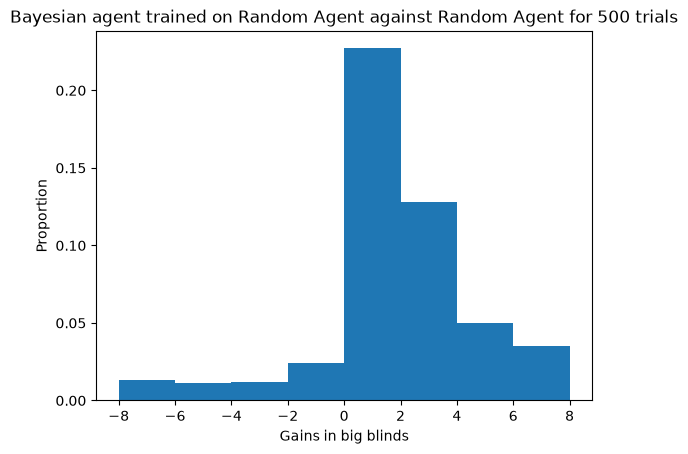

TOTALS:    702.5 ===== -702.5
WIN RATIO: 0.88 ===== 0.174
MEAN:      1.405 ===== -1.405
VARIANCE:  7.558 ===== 7.558
Likelihood the mean of BayesianAgent trained with None, (γ=1, r=0, μ=1, α=2, β=20) wins are different from 0: 0.0000


In [629]:
eval(agent_against_random, randomAgent, title="Bayesian agent trained on Random Agent against Random Agent for 500 trials")

In [621]:
env = rlcard.make(
    'leduc-holdem',
    config = {
        "allow_step_back" : True
    }
)

randomAgent = RandomAgent(env.num_actions)

agent_against_random = BayesianAgent(
    env,
    '/experiments',
    num_actions=env.num_actions
)


env.set_agents([agent_against_random, randomAgent])

In [622]:
for i in range(100_000):
    agent_against_random.train()

In [624]:
env = rlcard.make(
    'leduc-holdem',
)

agent_against_agent = BayesianAgent(env, '/experiments', num_actions=env.num_actions)

env.set_agents([agent_against_agent, agent_against_random])

In [625]:
for i in range(100000):
    agent_against_agent.train()

===== BayesianAgent trained with None, (γ=1, r=0, μ=1, α=2, β=20) ===== VS ===== BayesianAgent trained with None, (γ=1, r=0, μ=1, α=2, β=20) ======


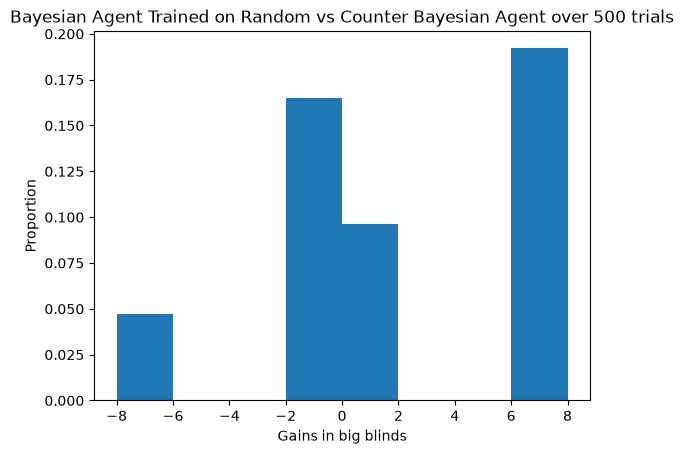

TOTALS:    598.0 ===== -598.0
WIN RATIO: 0.576 ===== 0.614
MEAN:      1.196 ===== -1.196
VARIANCE:  21.026 ===== 21.026
Likelihood the mean of BayesianAgent trained with None, (γ=1, r=0, μ=1, α=2, β=20) wins are different from 0: 0.0000


In [628]:
eval(agent_against_agent, agent_against_random, title='Bayesian Agent Trained on Random vs Counter Bayesian Agent over 500 trials')

In [1017]:
eval(agent_against_agent, agent_against_random)

===== BayesianAgent trained with None, (γ=1, r=0, μ=1, α=2, β=20) ===== VS ===== BayesianAgent trained with Random, (γ=1, r=0, μ=1, α=2, β=20) ======
TOTALS:    554.0 ===== -554.0
WIN RATIO: 0.542 ===== 0.458
MEAN:      1.108 ===== -1.108
VARIANCE:  26.950 ===== 26.950


In [1018]:
eval(randomAgent, randomAgent)

===== <rlcard.agents.random_agent.RandomAgent object at 0x0000025FA7F509F0> ===== VS ===== <rlcard.agents.random_agent.RandomAgent object at 0x0000025FA7F509F0> ======
TOTALS:    -6.0 ===== 6.0
WIN RATIO: 0.506 ===== 0.494
MEAN:      -0.012 ===== 0.012
VARIANCE:  3.251 ===== 3.251


===== BayesianAgent trained with Random, (γ=1, r=0, μ=1, α=2, β=20) ===== VS ===== <rlcard.agents.random_agent.RandomAgent object at 0x00000290F916D010> ======


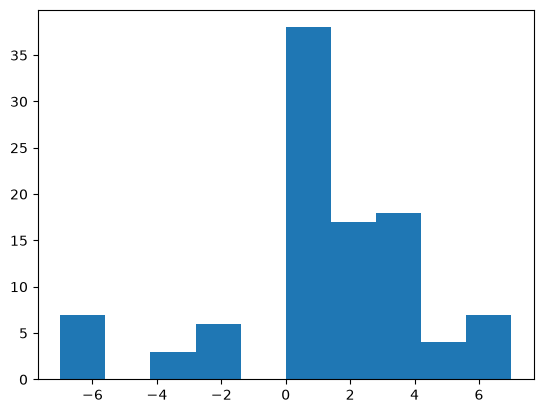

TOTALS:    119.5 ===== -119.5
WIN RATIO: 0.84 ===== 0.19
MEAN:      1.195 ===== -1.195
VARIANCE:  9.384 ===== 9.384
Likelihood the mean of BayesianAgent trained with Random, (γ=1, r=0, μ=1, α=2, β=20) wins are different from 0: 0.0002


In [14]:
eval(agent_against_random, randomAgent, n_trials=100)

In [250]:
from rlcard import models

cfr_agent = models.load('leduc-holdem-cfr').agents[0]


env = rlcard.make(
    'leduc-holdem',
)

randomAgent = RandomAgent(env.num_actions)

perfect_agent = BayesianAgent(
    env,
    '/experiments',
    num_actions=env.num_actions
)


env.set_agents([perfect_agent, cfr_agent])

In [ ]:
for i in range(100000):
    perfect_agent.train()
perfect_agent.trained_against = "CFR"

===== BayesianAgent trained with CFR, (γ=1, r=0, μ=1, α=2, β=20) ===== VS ===== <rlcard.agents.cfr_agent.CFRAgent object at 0x000002909563A210> ======


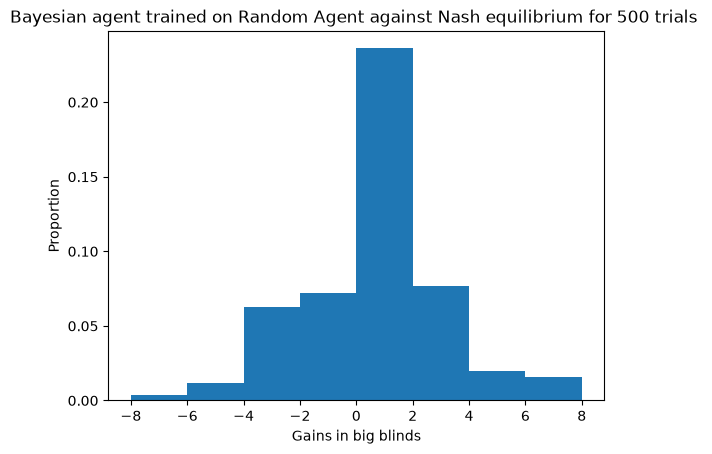

TOTALS:    125.5 ===== -125.5
WIN RATIO: 0.698 ===== 0.432
MEAN:      0.251 ===== -0.251
VARIANCE:  6.021 ===== 6.021
Likelihood the mean of BayesianAgent trained with CFR, (γ=1, r=0, μ=1, α=2, β=20) wins are different from 0: 0.0227


In [ ]:
eval(perfect_agent, cfr_agent, title="Bayesian agent trained on Random Agent against Nash equilibrium for 500 ")

===== BayesianAgent trained with None, (γ=1, r=0, μ=1, α=2, β=20) ===== VS ===== <rlcard.agents.cfr_agent.CFRAgent object at 0x000002909563A210> ======


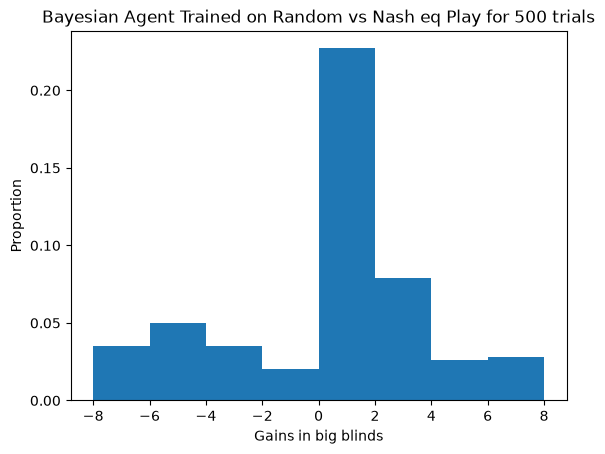

TOTALS:    -68.0 ===== 68.0
WIN RATIO: 0.72 ===== 0.384
MEAN:      -0.136 ===== 0.136
VARIANCE:  12.214 ===== 12.214
Likelihood the mean of BayesianAgent trained with None, (γ=1, r=0, μ=1, α=2, β=20) wins are different from 0: 0.3851


In [632]:
eval(agent_against_random, cfr_agent, title='Bayesian Agent Trained on Random vs Nash eq Play for 500 trials')

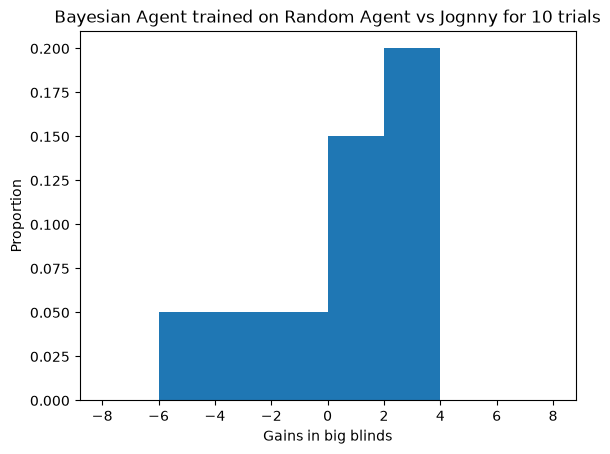

TOTALS:    -1.0 ===== 1.0
WIN RATIO: 0.7 ===== 0.6
MEAN:      -0.1 ===== 0.1
VARIANCE:  5.890 ===== 5.890
Likelihood the mean of Bayesian Agent's wins are different from 0: 0.9043


In [637]:
def jognny():
    total_a1 = 0
    total_a1_sqr = 0
    n_trials = 10
    total_a2 = 0
    total_a2_sqr = 0
    a_1_wins = np.array([4, 6, -4, -10, 4, 0, -6, 4,0,0 ]) /2
    a_2_wins =  -a_1_wins


    plt.hist(a_1_wins, bins=[-8, -6, -4, -2, 0 ,2, 4, 6, 8], density=True )
    plt.title(f"Bayesian Agent trained on Random Agent vs Jognny for 10 trials")
    plt.ylabel("Proportion")
    plt.xlabel("Gains in big blinds")
    plt.show()
    t_stat, p_value = stats.ttest_1samp(a_1_wins, 0)
    print(f"TOTALS:    {sum(a_1_wins)} ===== {sum(a_2_wins)}")
    print(f"WIN RATIO: {np.count_nonzero(a_1_wins >= a_2_wins) / n_trials} ===== {np.count_nonzero(a_1_wins <= a_2_wins)/n_trials}")
    print(f"MEAN:      {np.mean(a_1_wins)} ===== {np.mean(a_2_wins)}")
    print(f"VARIANCE:  {np.var(a_1_wins):.3f} ===== {np.var(a_2_wins):.3f}")
    print(f"Likelihood the mean of Bayesian Agent's wins are different from 0: {p_value:.4f}")
jognny()
    

In [ ]:
cfr_agent = models.load('leduc-holdem-cfr').agents[0]

In [ ]:



env = rlcard.make(
    'leduc-holdem',
)

randomAgent = RandomAgent(env.num_actions)

perfect_agent = BayesianAgent(
    env,
    '/experiments',
    num_actions=env.num_actions
)


env.set_agents([agent_against_random, randomAgent])

In [213]:
sm = 0
for i in range(100):
    sm += env.run()[1][0]
sm

np.float64(70.5)

## Evaluate agents
We need a way to compare two agents. Here it is.

In [ ]:

eval(agent, cfr_agent)


===== <__main__.BayesianAgent object at 0x0000025FA6D6CAD0> ===== VS ===== <rlcard.agents.cfr_agent.CFRAgent object at 0x0000025FA7A7A250> ======
TOTALS:    -183.5 ===== 183.5
WIN RATIO: 0.684 ===== 0.316
MEAN:      -0.367 ===== 0.367
VARIANCE:  12.192885771543086 ===== 12.192885771543086


### Play against the bot, manual mode

In [620]:

env = rlcard.make(
    'leduc-holdem',
)

randomAgent = RandomAgent(env.num_actions)

agent = agent_against_agent_random

env.set_agents([agent, randomAgent])

In [602]:
a = env.reset()

In [603]:
print(env.game.get_state(0))

env.agents

{'hand': 'SJ', 'public_card': None, 'all_chips': [2, 1], 'my_chips': 2, 'legal_actions': ['call', 'raise', 'fold'], 'current_player': 1}


Current Player:

In [604]:
id = env.get_player_id()
print("Player id:", id)
print("Agent:", env.agents[id])
print(env.game.get_state(id))

Player id: 1
Agent: <rlcard.agents.random_agent.RandomAgent object at 0x00000290933AE4E0>
{'hand': 'SQ', 'public_card': None, 'all_chips': [2, 1], 'my_chips': 1, 'legal_actions': ['call', 'raise', 'fold'], 'current_player': 1}


In [601]:
id = env.get_player_id()
state = env.get_state(id)
action, info = env.agents[id].eval_step(state)
print(env.actions[action])
s_key = agent._state_key(state)
q = agent.q[s_key]

print(env.get_state(0)['raw_obs'])
for i in range(4):
    print(i, env.actions[i], q[i].sample_normal_gamma()[0], q[i].lmbda)
env.step(action)
print()
print(f"Bayesian agent does {env.actions[action]}")

fold
{'hand': 'SQ', 'public_card': 'HJ', 'all_chips': [6, 10], 'my_chips': 6, 'legal_actions': ['call', 'raise', 'fold'], 'current_player': 0}
0 call [-4.45321655] 22
1 raise [-6.26867856] 12
2 fold [-2.99882936] 6597
3 check [0.19901668] 1

Bayesian agent does fold



Bayesian agent does raise


### Call:

In [596]:
env.step(0)
print('public card', env.get_perfect_information()['public_card'])

public card HJ


### Raise:

In [599]:
env.step(1)
print('public card', env.get_perfect_information()['public_card'])

public card HJ


### Fold:

In [121]:
env.step(2)
print('public card', env.get_perfect_information()['public_card'])

public card HQ


### Check:

In [428]:
env.step(3)
print('public card', env.get_perfect_information()['public_card'])

public card HK


In [844]:
id = env.get_player_id()
print("Player id:", id)
print("Agent:", env.agents[id])
state = env.get_state(id)
print(state)
print(state['raw_obs'])


Player id: 0
Agent: <__main__.BayesianAgent object at 0x0000025FA7BFBB10>
{'legal_actions': OrderedDict({0: None, 1: None, 2: None}), 'obs': array([0., 0., 1., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1.,
       0., 0.]), 'raw_obs': {'hand': 'SK', 'public_card': 'SQ', 'all_chips': [8, 12], 'my_chips': 8, 'legal_actions': ['call', 'raise', 'fold'], 'current_player': 0}, 'raw_legal_actions': ['call', 'raise', 'fold'], 'action_record': [(0, 'raise'), (1, 'call'), (0, 'raise'), (1, 'call'), (0, 'check'), (1, 'raise')]}
{'hand': 'SK', 'public_card': 'SQ', 'all_chips': [8, 12], 'my_chips': 8, 'legal_actions': ['call', 'raise', 'fold'], 'current_player': 0}


In [845]:
action, info = env.agents[id].eval_step(state)
print(action)
print(env.actions[action])
print(info)

1
raise
{'probs': {'call': 0, 'raise': 0, 'fold': 0}}


In [ ]:
s_key = agent._state_key(state)
q = agent.q[s_key]

print(env.get_state(0)['raw_obs'])
for i in range(4):
    print(i, env.actions[i], q[i].sample_normal_gamma()[0], q[i].lmbda)




{'hand': 'SK', 'public_card': 'SQ', 'all_chips': [8, 12], 'my_chips': 8, 'legal_actions': ['call', 'raise', 'fold'], 'current_player': 0}
0 call [1.21407079] 350
1 raise [3.44007836] 1
2 fold [-2.55103153] 5
3 check [-0.77474132] 1


In [847]:
env.step(1)

IndexError: index 37 is out of bounds for axis 0 with size 36

In [386]:
env.is_over()

False